In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

%matplotlib inline


In [2]:
def newton_grid(iterate, f, xmin, xmax, ymin, ymax, N, nmax=100, tol=1e-3):
    x = np.linspace(xmin, xmax, N)
    y = np.linspace(ymin, ymax, N)
    X, Y = np.meshgrid(x, y)
    Z = (X + 1j * Y).astype(complex)

    converged = np.zeros(Z.shape, dtype=bool)
    n_iter = np.full(Z.shape, nmax, dtype=int)

    with np.errstate(divide='ignore', invalid='ignore'):
        for n in range(1, nmax + 1):
            active = ~converged
            if not np.any(active):
                break
            Z[active] = iterate(Z[active])
            newly = np.zeros(Z.shape, dtype=bool)
            newly[active] = np.abs(f(Z[active])) < tol
            n_iter[newly] = n
            converged |= newly

    return Z, n_iter, converged


In [3]:
def classify_by_root(Z, roots, converged):
    roots = np.asarray(roots, dtype=complex)
    dists = np.stack([np.abs(Z - r) for r in roots], axis=0)
    idx = np.argmin(dists, axis=0).astype(float)
    idx[~converged] = len(roots)
    return idx


In [4]:
def f_cubic(z):
    return z**3 + 1

def fprime_cubic(z):
    return 3 * z**2

def iterate_cubic(z):
    return z - f_cubic(z) / fprime_cubic(z)


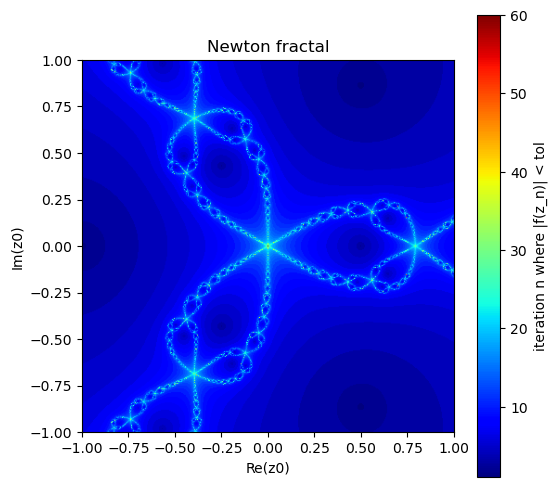

In [5]:
xmin, xmax = -1.0, 1.0
ymin, ymax = -1.0, 1.0
N = 401
nmax = 60
tol = 1e-3

Z_cubic, n_iter_cubic, converged_cubic = newton_grid(
    iterate_cubic, f_cubic, xmin, xmax, ymin, ymax, N, nmax=nmax, tol=tol
)

plt.figure(figsize=(6, 6))
plt.imshow(n_iter_cubic, extent=[xmin, xmax, ymin, ymax], origin='lower', cmap='jet')
plt.xlabel("Re(z0)")
plt.ylabel("Im(z0)")
plt.title(r"Newton fractal")
plt.colorbar(label="iteration n where |f(z_n)| < tol")
plt.show()


$f(z) = z^3+1 = 0 \;\Rightarrow\; z^3 = -1$, so $f$ has three complex roots. the three cube roots of -1. Writing $-1 = e^{i\pi}$, the roots are $e^{i(\pi+2\pi k)/3}$ for $k=0,1,2$, 


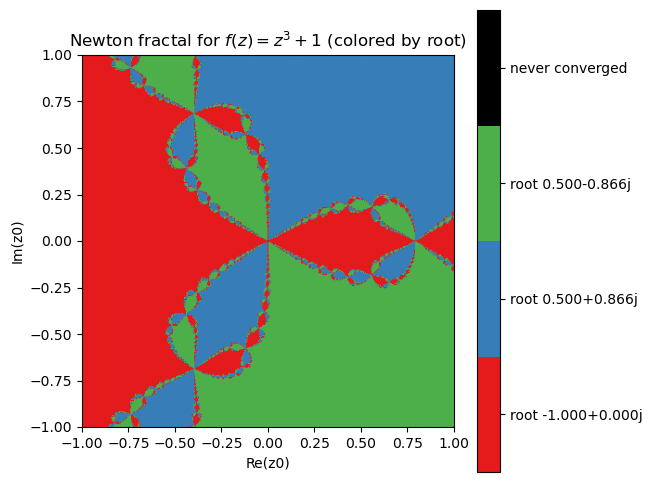

In [6]:
roots_cubic = [-1 + 0j, 0.5 + np.sqrt(3) / 2 * 1j, 0.5 - np.sqrt(3) / 2 * 1j]
root_idx_cubic = classify_by_root(Z_cubic, roots_cubic, converged_cubic)

colors_cubic = ['#e41a1c', '#377eb8', '#4daf4a', 'black']
cmap_cubic = ListedColormap(colors_cubic)

plt.figure(figsize=(6, 6))
im = plt.imshow(root_idx_cubic, extent=[xmin, xmax, ymin, ymax], origin='lower',
                 cmap=cmap_cubic, vmin=-0.5, vmax=len(colors_cubic) - 0.5)
plt.xlabel("Re(z0)")
plt.ylabel("Im(z0)")
plt.title(r"Newton fractal for $f(z)=z^3+1$ (colored by root)")
cbar = plt.colorbar(im, ticks=range(len(colors_cubic)))
cbar.ax.set_yticklabels([f"root {r:.3f}" for r in roots_cubic] + ["never converged"])
plt.show()


In [7]:
def make_power_functions(n):
    def f(z):
        return z**n + 1

    def fprime(z):
        return n * z**(n - 1)

    def iterate(z):
        return z - f(z) / fprime(z)

    return iterate, f


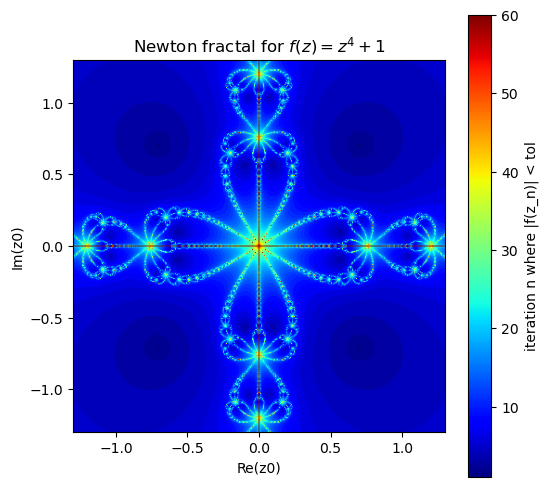

Saved newton_fractal_z4_plus_1.png


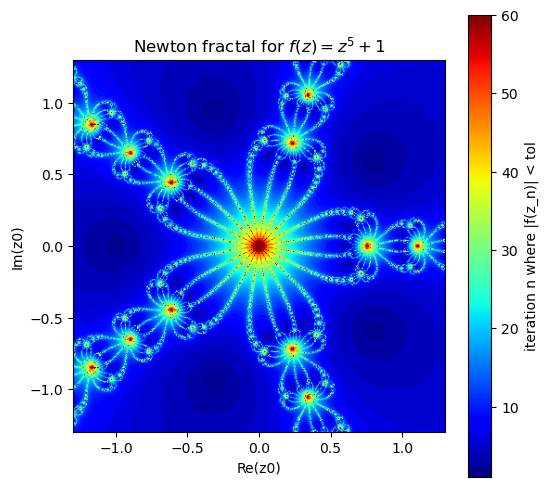

Saved newton_fractal_z5_plus_1.png


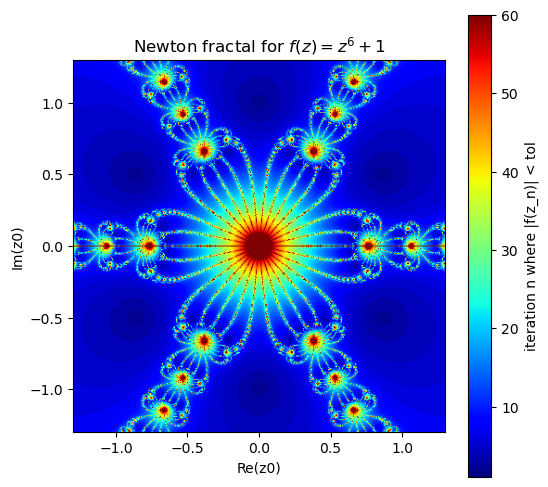

Saved newton_fractal_z6_plus_1.png


In [8]:
power_results = {}

for n in [4, 5, 6]:
    iterate_n, f_n = make_power_functions(n)
    Zn, n_iter_n, converged_n = newton_grid(
        iterate_n, f_n, xmin=-1.3, xmax=1.3, ymin=-1.3, ymax=1.3, N=401, nmax=60, tol=1e-3
    )
    power_results[n] = (Zn, n_iter_n, converged_n)

    plt.figure(figsize=(6, 6))
    plt.imshow(n_iter_n, extent=[-1.3, 1.3, -1.3, 1.3], origin='lower', cmap='jet')
    plt.xlabel("Re(z0)")
    plt.ylabel("Im(z0)")
    plt.title(f"Newton fractal for $f(z)=z^{{{n}}}+1$")
    plt.colorbar(label="iteration n where |f(z_n)| < tol")

    fname = f"newton_fractal_z{n}_plus_1.png"
    plt.savefig(fname, dpi=200, bbox_inches='tight')
    plt.show()
    print(f"Saved {fname}")


In [9]:
za = 1.2 + 0.3j
zb = -0.8 + 0.9j
zc = -1.0 - 0.6j
zd = 0.4 - 1.1j
roots_quartic = [za, zb, zc, zd]

def f_quartic(z):
    return (z - za) * (z - zb) * (z - zc) * (z - zd)

def fprime_quartic(z):
    return (
        (z - zb) * (z - zc) * (z - zd)
        + (z - za) * (z - zc) * (z - zd)
        + (z - za) * (z - zb) * (z - zd)
        + (z - za) * (z - zb) * (z - zc)
    )

def iterate_quartic(z):
    return z - f_quartic(z) / fprime_quartic(z)


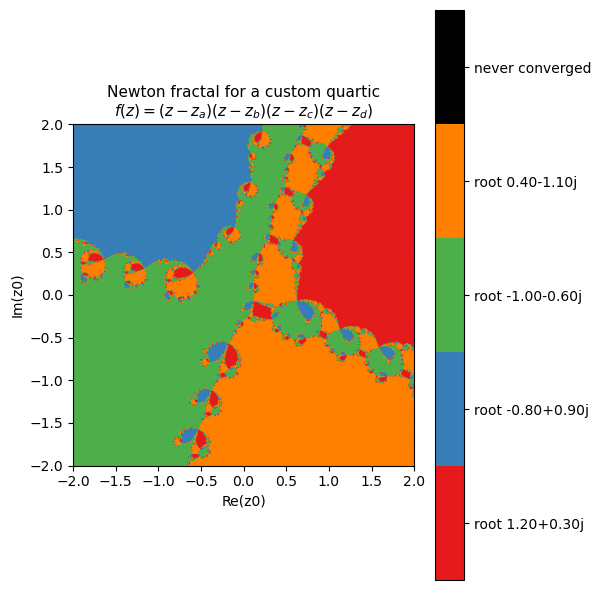

Saved newton_fractal_custom_quartic.png
z0 interval used: Re(z0) in [-2.0, 2.0], Im(z0) in [-2.0, 2.0]
Roots used: za=(1.2+0.3j), zb=(-0.8+0.9j), zc=(-1-0.6j), zd=(0.4-1.1j)


In [10]:
qxmin, qxmax = -2.0, 2.0
qymin, qymax = -2.0, 2.0

Z_quartic, n_iter_quartic, converged_quartic = newton_grid(
    iterate_quartic, f_quartic, qxmin, qxmax, qymin, qymax, N=401, nmax=80, tol=1e-3
)
root_idx_quartic = classify_by_root(Z_quartic, roots_quartic, converged_quartic)

colors_quartic = ['#e41a1c', '#377eb8', '#4daf4a', '#ff7f00', 'black']  # 4 roots + "never converged"
cmap_quartic = ListedColormap(colors_quartic)

plt.figure(figsize=(6, 6))
im = plt.imshow(root_idx_quartic, extent=[qxmin, qxmax, qymin, qymax], origin='lower',
                 cmap=cmap_quartic, vmin=-0.5, vmax=len(colors_quartic) - 0.5)
plt.xlabel("Re(z0)")
plt.ylabel("Im(z0)")
plt.title("Newton fractal for a custom quartic\n" + r"$f(z)=(z-z_a)(z-z_b)(z-z_c)(z-z_d)$",
          fontsize=11)
cbar = plt.colorbar(im, ticks=range(len(colors_quartic)))
cbar.ax.set_yticklabels([f"root {r:.2f}" for r in roots_quartic] + ["never converged"])
plt.tight_layout()

fname = "newton_fractal_custom_quartic.png"
plt.savefig(fname, dpi=200, bbox_inches='tight')
plt.show()
print(f"Saved {fname}")
print(f"z0 interval used: Re(z0) in [{qxmin}, {qxmax}], Im(z0) in [{qymin}, {qymax}]")
print(f"Roots used: za={za}, zb={zb}, zc={zc}, zd={zd}")
